# Can You Beat the Spread in College Football?

Using 2021–2025 Power 4 data from the CFBD API, we ask two questions:
1. How often is Vegas right?
2. Can a model built on team quality metrics predict whether a team beats the spread?

## Setup

## Install and Import Packages
optuna: This package is a library used for hyperparameter tuning, it automatically searches for the best settings for the XGBoost model we will be using

In [255]:
!pip install cfbd xgboost optuna -q


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [256]:
import cfbd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'

## 1. Fetch Betting Lines (2021–2025)

In [ ]:
config = cfbd.Configuration(
    access_token='enter your cfbd access token here'
)
api_client = cfbd.ApiClient(config)
betting_api = cfbd.BettingApi(api_client)

all_lines = []
for year in [2021, 2022, 2023, 2024, 2025]:
    print(f'Fetching {year}...')
    data = betting_api.get_lines(year=year)
    all_lines.extend(data)

print(f'Total game records: {len(all_lines)}')

Fetching 2021...
Fetching 2022...
Fetching 2023...
Fetching 2024...
Fetching 2025...
Total game records: 6936


## 2. Build & Clean DataFrame

Each game has lines from multiple providers (Bovada, DraftKings, etc.). Take the median spread and over/under across providers to get one consensus line per game. This is more robust than the mean since it ignores outliers. 

In [258]:
P4_CONFERENCES = {'SEC', 'Big Ten', 'Big 12', 'ACC'}

rows = []
for game in all_lines:
    # filter to only games where both teams are in the Power 4 conferences
    if game.home_conference not in P4_CONFERENCES or game.away_conference not in P4_CONFERENCES:
        continue
    # each game has multiple lines from different providers, this loops through all of them
    for line in game.lines:
        rows.append({
            'game_id': game.id,
            'season': game.season,
            'week': game.week,
            'start_date': game.start_date,
            'home_team': game.home_team,
            'away_team': game.away_team,
            'home_score': game.home_score,
            'away_score': game.away_score,
            'home_conference': game.home_conference,
            'away_conference': game.away_conference,
            'provider': line.provider,
            'spread': line.spread,
            'over_under': line.over_under,
            'home_moneyline': line.home_moneyline,
            'away_moneyline': line.away_moneyline,
        })

# this has one row per provider per game
raw_df = pd.DataFrame(rows)


# this collapses multiple provider lines into a single row per game, using the median spread and over/under
df = (
    raw_df.groupby(['game_id', 'season', 'week', 'start_date',
                    'home_team', 'away_team', 'home_score', 'away_score',
                    'home_conference', 'away_conference'])
    .agg(spread=('spread', 'median'), over_under=('over_under', 'median'))
    .reset_index()
)

# drop games with missing scores or spreads
df = df.dropna(subset=['home_score', 'away_score', 'spread'])

# feature engineering

# how much the home team won or lost by
# positive means the home team won by that many points, negative means the home team lost by that many points
df['actual_margin'] = df['home_score'] - df['away_score']

# total points scored in game
# used to evaluate the over/under
df['total_scored'] = df['home_score'] + df['away_score']

# did the home team beat the spread?
# spread is negative when the home team is favored (ex: spread = -7 means home must win by 7+ points)
# actual margin + spread > 0 means the home team outperformed what Vegas expected
df['covered'] = df['actual_margin'] + df['spread'] > 0

# was the home team favored?
df['home_favored'] = df['spread'] < 0

# did the favorite team win?
df['favorite_won'] = (
    (df['home_favored'] & (df['actual_margin'] > 0)) |
    (~df['home_favored'] & (df['actual_margin'] < 0))
)

# did the total points exceed the over/under line?
df['over_hit'] = df['total_scored'] > df['over_under']

print(f'P4 games after dedup + clean: {len(df)}')
df.head()

P4 games after dedup + clean: 1486


,game_id,season,week,start_date,home_team,away_team,home_score,away_score,home_conference,away_conference,spread,over_under,actual_margin,total_scored,covered,home_favored,favorite_won,over_hit
0,401281942,2021,1,2021-09-04 19:30:00+00:00,Miami,Alabama,13,44,ACC,SEC,19.5,61.5,-31,57,False,False,True,False
1,401281946,2021,1,2021-09-04 23:30:00+00:00,Clemson,Georgia,3,10,ACC,SEC,-2.5,51.5,-7,13,False,True,False,False
2,401282055,2021,1,2021-09-07 00:00:00+00:00,Ole Miss,Louisville,43,24,SEC,ACC,-9.0,74.5,19,67,True,True,True,False
3,401282057,2021,2,2021-09-11 23:00:00+00:00,Arkansas,Texas,40,21,SEC,Big 12,6.0,57.5,19,61,True,False,False,True
4,401282061,2021,2,2021-09-11 23:30:00+00:00,Kentucky,Missouri,35,28,SEC,SEC,-5.5,56.5,7,63,True,True,True,True


## 3. Fetch SP+ Ratings

SP+ is a preseason composite rating (offense, defense, special teams) set before games are played.

In [259]:
ratings_api = cfbd.RatingsApi(api_client)

sp_rows = []
for year in [2021, 2022, 2023, 2024, 2025]:
    print(f'Fetching SP+ {year}...')
    data = ratings_api.get_sp(year=year)
    for r in data:
        sp_rows.append({
            'season': year,
            'team': r.team,
            'sp_rating': r.rating,
            'sp_offense': r.offense.rating,
            'sp_defense': r.defense.rating,
        })

sp_df = pd.DataFrame(sp_rows).dropna(subset=['sp_rating'])
print(f'SP+ records: {len(sp_df)}')
sp_df.head()

Fetching SP+ 2021...
Fetching SP+ 2022...
Fetching SP+ 2023...
Fetching SP+ 2024...
Fetching SP+ 2025...
SP+ records: 669


,season,team,sp_rating,sp_offense,sp_defense
0,2021,Georgia,32.0,41.4,10.3
1,2021,Ohio State,29.3,47.2,20.6
2,2021,Alabama,26.0,40.9,15.6
3,2021,Michigan,23.4,36.5,15.8
4,2021,Cincinnati,21.2,37.5,15.9


In [260]:
# merge SP+ for home team
df = df.merge(
    sp_df.rename(columns={'team': 'home_team', 'sp_rating': 'home_sp',
                           'sp_offense': 'home_sp_off', 'sp_defense': 'home_sp_def'}),
    on=['season', 'home_team'], how='left'
)

# merge SP+ for away team
df = df.merge(
    sp_df.rename(columns={'team': 'away_team', 'sp_rating': 'away_sp',
                           'sp_offense': 'away_sp_off', 'sp_defense': 'away_sp_def'}),
    on=['season', 'away_team'], how='left'
)

df['sp_diff'] = df['home_sp'] - df['away_sp'] 

print(f'After SP+ merge: {len(df)} games, {df["home_sp"].isna().sum()} missing home SP+')
df[['home_team', 'away_team', 'home_sp', 'away_sp', 'sp_diff']].head()

After SP+ merge: 1486 games, 0 missing home SP+


,home_team,away_team,home_sp,away_sp,sp_diff
0,Miami,Alabama,10.8,26.0,-15.2
1,Clemson,Georgia,18.7,32.0,-13.3
2,Ole Miss,Louisville,14.8,7.8,7.0
3,Arkansas,Texas,13.8,8.5,5.3
4,Kentucky,Missouri,13.4,3.1,10.3


## 3b. Fetch Elo Ratings (Week-by-Week)

Elo updates after every game, so it captures current form going into each matchup — better than preseason SP+ alone for mid/late season games. We fetch each team's Elo at the week before the game.

In [261]:
elo_rows = []
for year in [2021, 2022, 2023, 2024, 2025]:
    print(f'Fetching Elo {year}...')
    # get weeks 1-16
    # week 0 is preseason opening Elo
    for week in range(1, 17):
        try:
            data = ratings_api.get_elo(year=year, week=week)
            for r in data:
                if r.elo is not None:
                    elo_rows.append({'season': year, 'week': week, 'team': r.team, 'elo': r.elo})
        except Exception:
            break 

elo_df = pd.DataFrame(elo_rows)
print(f'Elo records: {len(elo_df)}')
elo_df.head()

Fetching Elo 2021...
Fetching Elo 2022...
Fetching Elo 2023...
Fetching Elo 2024...
Fetching Elo 2025...
Elo records: 10589


,season,week,team,elo
0,2021,1,Akron,1028
1,2021,1,Alabama,2121
2,2021,1,App State,1666
3,2021,1,Arizona,1304
4,2021,1,Arkansas,1470


In [262]:
# for each game in week w, get the team's Elo from week W-1
# the most recent rating before the game was played
elo_prev = elo_df.copy()
elo_prev['week'] = elo_prev['week'] + 1 

df = df.merge(
    elo_prev.rename(columns={'team': 'home_team', 'elo': 'home_elo'})[['season', 'week', 'home_team', 'home_elo']],
    on=['season', 'week', 'home_team'], how='left'
)
df = df.merge(
    elo_prev.rename(columns={'team': 'away_team', 'elo': 'away_elo'})[['season', 'week', 'away_team', 'away_elo']],
    on=['season', 'week', 'away_team'], how='left'
)
df['elo_diff'] = df['home_elo'] - df['away_elo']

missing = df['home_elo'].isna().sum()
print(f'Games with Elo: {len(df) - missing} / {len(df)} ({missing} missing, likely week 1 with no prior week)')
df[['home_team', 'away_team', 'week', 'home_elo', 'away_elo', 'elo_diff']].head()

Games with Elo: 1354 / 1486 (132 missing, likely week 1 with no prior week)


,home_team,away_team,week,home_elo,away_elo,elo_diff
0,Miami,Alabama,1,NaN,NaN,NaN
1,Clemson,Georgia,1,NaN,NaN,NaN
2,Ole Miss,Louisville,1,NaN,NaN,NaN
3,Arkansas,Texas,2,1470.0,1801.0,-331.0
4,Kentucky,Missouri,2,1593.0,1515.0,78.0


## 4. Rolling Win %

For each game, compute the team's win percentage in games before that week in that season. This captures in-season momentum.

In [263]:
# build a flat win/loss record per team per game
home_records = df[['game_id', 'season', 'week', 'home_team', 'actual_margin']].copy()
home_records.columns = ['game_id', 'season', 'week', 'team', 'margin']
home_records['won'] = home_records['margin'] > 0

away_records = df[['game_id', 'season', 'week', 'away_team', 'actual_margin']].copy()
away_records.columns = ['game_id', 'season', 'week', 'team', 'margin']
away_records['won'] = away_records['margin'] < 0 

records = pd.concat([home_records, away_records], ignore_index=True)
records = records.sort_values(['team', 'season', 'week'])

# cumulative wins/games before the current game (shift by 1)
records['cum_wins'] = records.groupby(['team', 'season'])['won'].cumsum().shift(1).fillna(0)
records['cum_games'] = records.groupby(['team', 'season']).cumcount()  
records['win_pct'] = records.apply(
    lambda r: r['cum_wins'] / r['cum_games'] if r['cum_games'] > 0 else 0.5, axis=1
)

# merge back, home team win %
home_wp = records[['game_id', 'team', 'win_pct']].rename(
    columns={'team': 'home_team', 'win_pct': 'home_win_pct'}
)
away_wp = records[['game_id', 'team', 'win_pct']].rename(
    columns={'team': 'away_team', 'win_pct': 'away_win_pct'}
)

df = df.merge(home_wp, on=['game_id', 'home_team'], how='left')
df = df.merge(away_wp, on=['game_id', 'away_team'], how='left')

df['win_pct_diff'] = df['home_win_pct'] - df['away_win_pct']

print(f'Dataset shape: {df.shape}')
df[['home_team', 'away_team', 'week', 'home_win_pct', 'away_win_pct']].head(10)

Dataset shape: (1486, 31)


,home_team,away_team,week,home_win_pct,away_win_pct
0,Miami,Alabama,1,0.5,0.0
1,Clemson,Georgia,1,0.5,0.5
2,Ole Miss,Louisville,1,0.5,0.5
3,Arkansas,Texas,2,1.0,0.5
4,Kentucky,Missouri,2,1.0,0.5
5,Mississippi State,NC State,2,0.0,0.5
6,Tennessee,Pittsburgh,2,0.0,0.0
7,Penn State,Auburn,3,0.5,0.5
8,Florida,Alabama,3,0.5,0.5
9,Georgia,South Carolina,3,1.0,1.0


---
# How Often is Vegas Right?

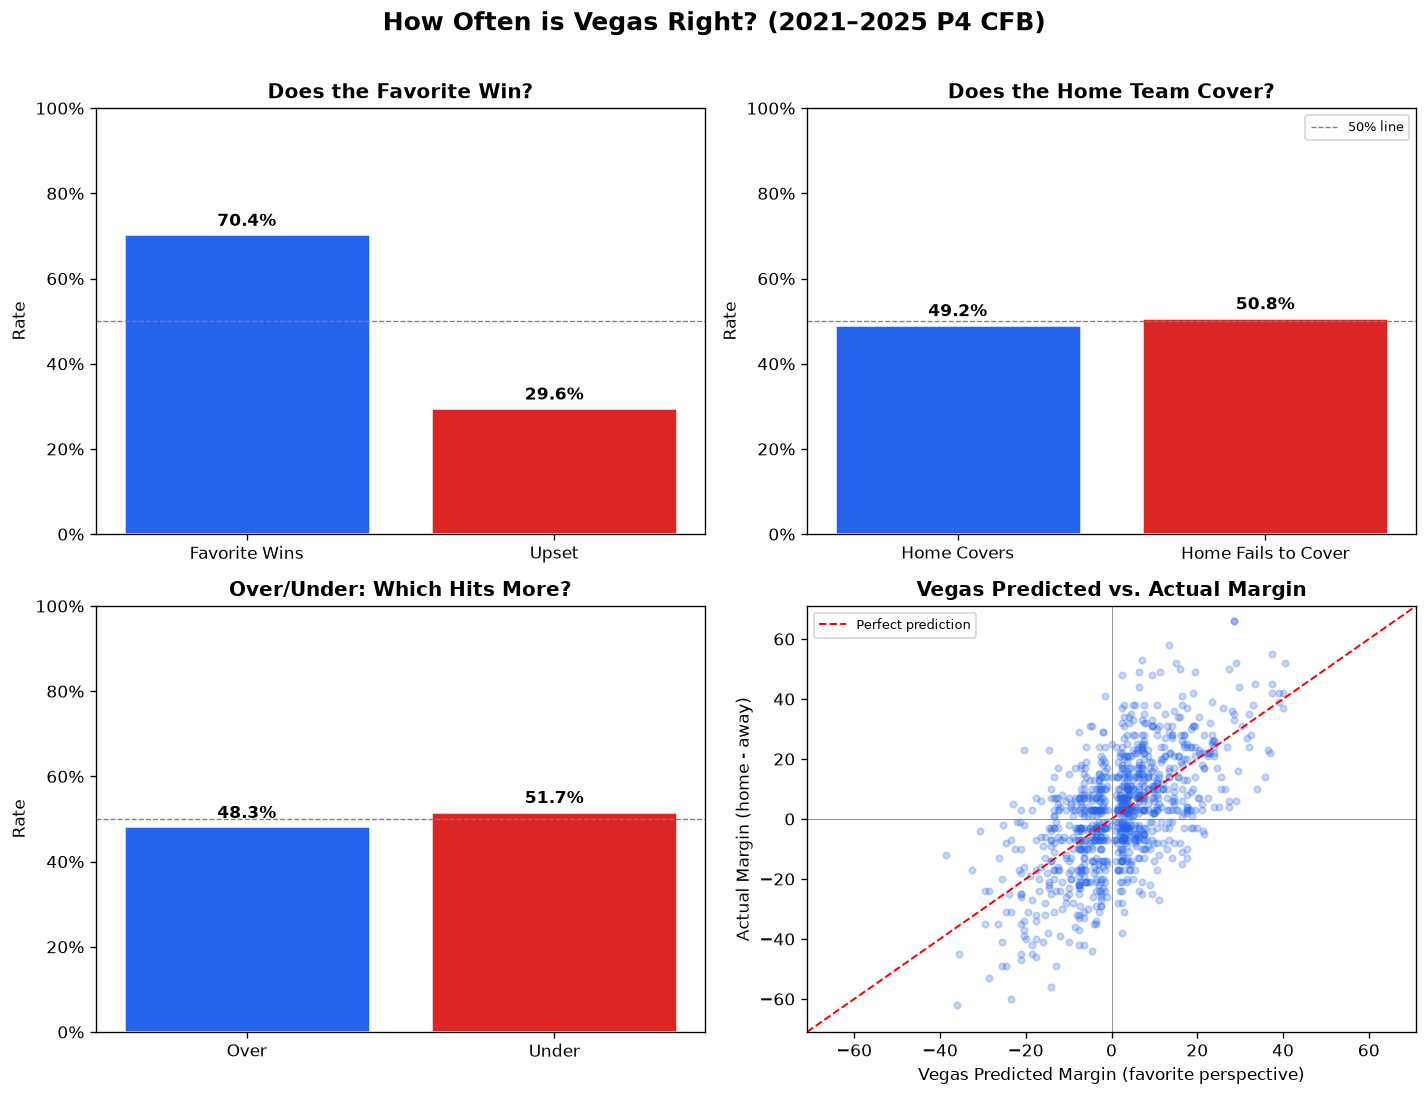

Favorite win rate: 70.4%
Home cover rate:   49.2%
Over hit rate:     48.3%


In [264]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle('How Often is Vegas Right? (2021–2025 P4 CFB)', fontsize=15, fontweight='bold', y=1.01)

bar_color = '#2563eb'
accent = '#dc2626'

# favorite win rate 
ax = axes[0, 0]
fav_win_rate = df['favorite_won'].mean()
ax.bar(['Favorite Wins', 'Upset'], [fav_win_rate, 1 - fav_win_rate],
       color=[bar_color, accent], edgecolor='white', linewidth=1.5)
ax.set_title('Does the Favorite Win?', fontweight='bold')
ax.set_ylabel('Rate')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
for i, v in enumerate([fav_win_rate, 1 - fav_win_rate]):
    ax.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

# spread cover rate
ax = axes[0, 1]
cover_rate = df['covered'].mean()
ax.bar(['Home Covers', 'Home Fails to Cover'], [cover_rate, 1 - cover_rate],
       color=[bar_color, accent], edgecolor='white', linewidth=1.5)
ax.set_title('Does the Home Team Cover?', fontweight='bold')
ax.set_ylabel('Rate')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, label='50% line')
ax.legend(fontsize=8)
for i, v in enumerate([cover_rate, 1 - cover_rate]):
    ax.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

# over/under rate
ax = axes[1, 0]
ou_valid = df.dropna(subset=['over_under'])
over_rate = ou_valid['over_hit'].mean()
ax.bar(['Over', 'Under'], [over_rate, 1 - over_rate],
       color=[bar_color, accent], edgecolor='white', linewidth=1.5)
ax.set_title('Over/Under: Which Hits More?', fontweight='bold')
ax.set_ylabel('Rate')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
for i, v in enumerate([over_rate, 1 - over_rate]):
    ax.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

# spread vs actual margin scatter
ax = axes[1, 1]
sample = df.sample(min(1000, len(df)), random_state=42)
ax.scatter(-sample['spread'], sample['actual_margin'],
           alpha=0.25, s=15, color=bar_color)
lim = max(abs(sample['actual_margin'].max()), abs(sample['spread'].min())) + 5
ax.plot([-lim, lim], [-lim, lim], 'r--', linewidth=1.2, label='Perfect prediction')
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel('Vegas Predicted Margin (favorite perspective)')
ax.set_ylabel('Actual Margin (home - away)')
ax.set_title('Vegas Predicted vs. Actual Margin', fontweight='bold')
ax.legend(fontsize=8)
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)

plt.tight_layout()
plt.savefig('part1_eda.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Favorite win rate: {fav_win_rate:.1%}')
print(f'Home cover rate:   {cover_rate:.1%}')
print(f'Over hit rate:     {over_rate:.1%}')

Favorite win rate: 70.4%
- The team Vegas picked to win actually won the game 70.4% of the time.

Home cover rate:   49.2%
- The home team beat the spread only 49.2% of the time
- Vegas designs the spread to split bettors 50/50

Over hit rate:     48.3%
- The total points scored went over Vegas's over/under line 48.3% of the time

---
# Can a Model Beat the Spread?

Build an XGBoost gradient boosted tree model using only pre-game team quality metrics.
The goal is to have a model that succesfully predicts whether a team beats the spread more than Vegas.

**Features used:**
- SP+ rating (home, away, difference)
- SP+ offense and defense (home and away)
- Elo rating (home, away, difference)
- Rolling win % going into the game
- Week of season, season year

**Target:** `covered` - did the home team beat the spread?

**Train:** 2021–2023 | **Val:** 2024 (used for Optuna hyperparameter tuning) | **Test:** 2025

In [265]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# features for data
model_df = df.dropna(subset=['home_sp', 'away_sp', 'home_elo', 'away_elo',
                              'home_win_pct', 'away_win_pct', 'covered']).copy()

FEATURES = [
    'home_sp', 'away_sp', 'sp_diff',
    'home_sp_off', 'away_sp_off', 'home_sp_def', 'away_sp_def',
    'home_elo', 'away_elo', 'elo_diff',
    'home_win_pct', 'away_win_pct', 'win_pct_diff',
    'week', 'season'
]
TARGET = 'covered'

train = model_df[model_df['season'] <= 2023]
val   = model_df[model_df['season'] == 2024]
test  = model_df[model_df['season'] == 2025]

X_train = train[FEATURES].values
X_val   = val[FEATURES].values
X_test  = test[FEATURES].values

y_train = train[TARGET].astype(int).values
y_val   = val[TARGET].astype(int).values
y_test  = test[TARGET].astype(int).values

print(f'Train: {len(train)} | Val: {len(val)} | Test: {len(test)}')

Train: 729 | Val: 315 | Test: 310


### Model: XGBoost Gradient Boosted Trees

XGBoost builds an ensemble of decision trees, each one correcting the errors of the previous. It naturally captures non-linear interactions between features (e.g. SP+ diff matters differently in week 1 vs. week 12) without needing a large dataset.

We use early stopping on the validation set (2024) to prevent overfitting.

In [266]:
def objective(trial):
    params = {
        # number of trees to build
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        # how deep each tree can grow
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        # how much each tree contributes to the final prediction
        # lower is slower learning but more stable
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        # fraction of training rows used to build each tree
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        # fraction of features used to build each tree
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        # minimum number of games required in leaf node
        # higher values make the model simpler
        'min_child_weight': trial.suggest_int('min_child_weight', 3, 15),
        # minimum loss reduction required to make a further partition on a leaf node
        # higher values make the tree only split when it is more clearly worth it
        'gamma': trial.suggest_float('gamma', 0, 1),
        # loss function used
        'eval_metric': 'logloss',
        # stops iteration if no improvement is seen for this many rounds
        'early_stopping_rounds': 20,
        # random seed for reproducibility
        'random_state': 302,
        # prevents verbose output from the model
        'verbosity': 0,
    }
    m = xgb.XGBClassifier(**params)
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    return accuracy_score(y_val, m.predict(X_val))

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

print(f'\nBest val accuracy: {study.best_value:.1%}')
print(f'Best params: {study.best_params}')

  0%|          | 0/100 [00:00<?, ?it/s]


Best val accuracy: 65.7%
Best params: {'n_estimators': 315, 'max_depth': 2, 'learning_rate': 0.07110527614569642, 'subsample': 0.7921432799858539, 'colsample_bytree': 0.6616680606248492, 'min_child_weight': 12, 'gamma': 0.9375621654481151}


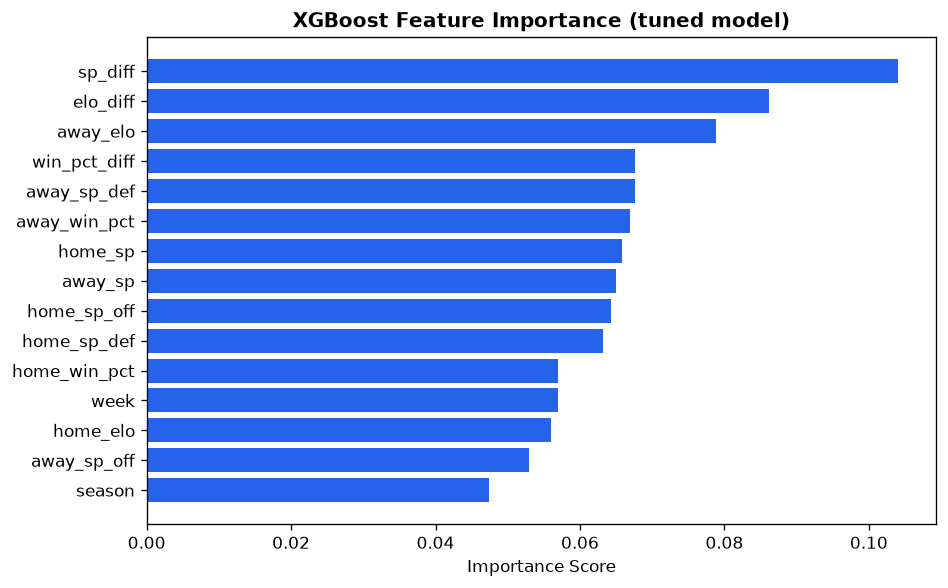

In [267]:
# re-train model with best hyperparameters on train+val, evaluate on test
best_params = study.best_params
best_params.update({'eval_metric': 'logloss', 'random_state': 42, 'verbosity': 0})

model = xgb.XGBClassifier(**best_params)
model.fit(
    np.vstack([X_train, X_val]),
    np.concatenate([y_train, y_val]),
)

# feature importance
fig, ax = plt.subplots(figsize=(8, 5))
importances = model.feature_importances_
sorted_idx = np.argsort(importances)
ax.barh([FEATURES[i] for i in sorted_idx], importances[sorted_idx], color='#2563eb')
ax.set_title('XGBoost Feature Importance (tuned model)', fontweight='bold')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

## 5. Results

In [268]:
y_pred = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]

model_acc = accuracy_score(y_test, y_pred)
naive_acc = max(y_test.mean(), 1 - y_test.mean())

# vegas accuracy: negative spread = home favored = vegas predicts home covers
vegas_pred = (test['spread'] < 0).astype(int).values
vegas_acc  = accuracy_score(y_test, vegas_pred)

print(f'Model accuracy (2025 test): {model_acc:.1%}')
print(f'Vegas accuracy (2025 test): {vegas_acc:.1%}')
print(f'Naive baseline:             {naive_acc:.1%}')
print(f'Breakeven for profitability: 52.4%')

Model accuracy (2025 test): 61.3%
Vegas accuracy (2025 test): 50.3%
Naive baseline:             50.3%
Breakeven for profitability: 52.4%


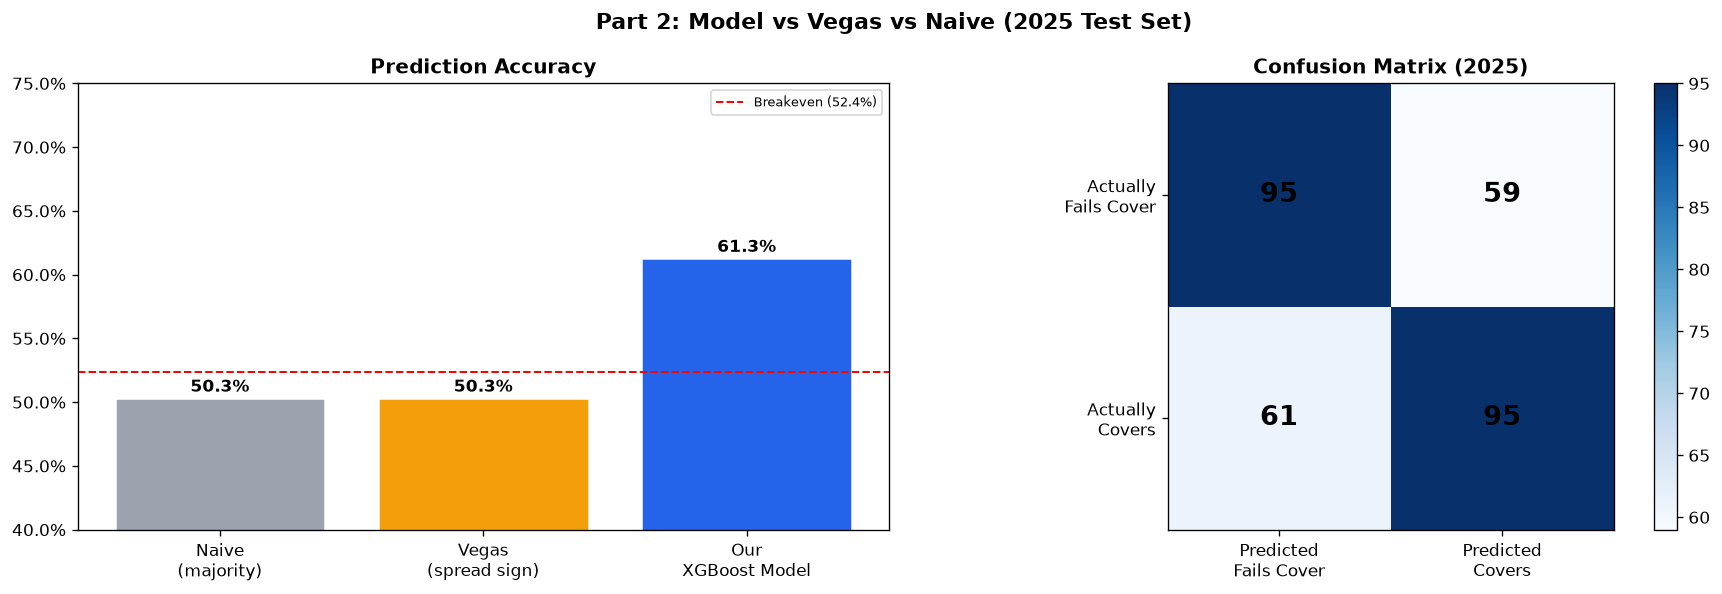

In [272]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Part 2: Model vs Vegas vs Naive (2025 Test Set)', fontsize=13, fontweight='bold')

# accuracy comparison bar chart
ax = axes[0]
labels = ['Naive\n(majority)', 'Vegas\n(spread sign)', 'Our\nXGBoost Model']
accs   = [naive_acc, vegas_acc, model_acc]
colors = ['#9ca3af', '#f59e0b', '#2563eb']
bars = ax.bar(labels, accs, color=colors, edgecolor='white', linewidth=1.5)
ax.axhline(0.524, color='red', linestyle='--', linewidth=1.2, label='Breakeven (52.4%)')
ax.set_ylim(0.4, 0.75)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('Prediction Accuracy', fontweight='bold')
ax.legend(fontsize=8)
for bar, v in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005,
            f'{v:.1%}', ha='center', fontweight='bold', fontsize=10)

# confusion matrix
ax = axes[1]
cm = confusion_matrix(y_test, y_pred)
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Predicted\nFails Cover', 'Predicted\nCovers'])
ax.set_yticklabels(['Actually\nFails Cover', 'Actually\nCovers'])
ax.set_title('Confusion Matrix (2025)', fontweight='bold')
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                fontsize=16, fontweight='bold', color='black')
plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('part2_results.png', bbox_inches='tight', dpi=150)
plt.show()

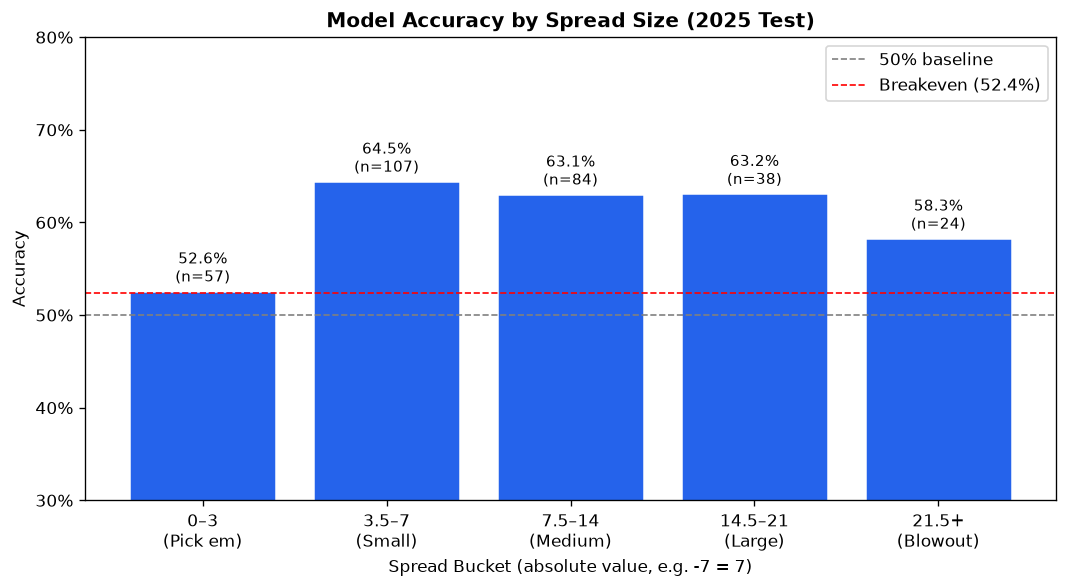

In [270]:
# model accuracy broken down by spread bucket (how big was the line?)
test_results = test.copy()
test_results['y_pred'] = y_pred
test_results['y_true'] = y_test
test_results['correct'] = test_results['y_pred'] == test_results['y_true']
test_results['abs_spread'] = test_results['spread'].abs()
test_results['spread_bucket'] = pd.cut(
    test_results['abs_spread'],
    bins=[0, 3, 7, 14, 21, 100],
    labels=['0–3\n(Pick em)', '3.5–7\n(Small)', '7.5–14\n(Medium)', '14.5–21\n(Large)', '21.5+\n(Blowout)']
)

bucket_acc = test_results.groupby('spread_bucket', observed=True)['correct'].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(bucket_acc.index.astype(str), bucket_acc['mean'],
              color='#2563eb', edgecolor='white', linewidth=1.5)
ax.axhline(0.5,   color='gray', linestyle='--', linewidth=1, label='50% baseline')
ax.axhline(0.524, color='red',  linestyle='--', linewidth=1, label='Breakeven (52.4%)')
ax.set_title('Model Accuracy by Spread Size (2025 Test)', fontweight='bold')
ax.set_xlabel('Spread Bucket (absolute value, e.g. -7 = 7)')
ax.set_ylabel('Accuracy')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0.3, 0.8)
ax.legend()
for bar, (_, row) in zip(bars, bucket_acc.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, row['mean'] + 0.01,
            f"{row['mean']:.1%}\n(n={int(row['count'])})",
            ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('part2_by_spread.png', bbox_inches='tight', dpi=150)
plt.show()

---
## Homework Problem: 2026 Season Predictions

Does the model holdup in the 2026 season? 